# Unidad 3: Funciones, Visualización y Tasas de Cambio
## Álgebra — Tecnicatura en Ciencia de Datos e IA

**Objetivos de esta notebook:**
- Implementar y graficar la función de costo MSE
- Visualizar superficies de costo en 3D
- Calcular derivadas numéricas y simbólicas
- Ver la recta tangente como representación de la derivada
- Usar SymPy para obtener fórmulas exactas del gradiente

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import sympy as sp

# Dataset: tamaño (m²) y precio real
x_data = np.array([60.0, 85.0, 120.0, 150.0, 200.0])   # size_m2
y_data = np.array([120000.0, 150000.0, 180000.0, 210000.0, 250000.0])  # price_usd

print("Datos del curso:")
for xi, yi in zip(x_data, y_data):
    print(f"  {xi:.0f} m²  →  ${yi:,.0f}")

Datos del curso:
  60 m²  →  $120,000
  85 m²  →  $150,000
  120 m²  →  $180,000
  150 m²  →  $210,000
  200 m²  →  $250,000


## 1. La Función de Costo: MSE

Para un modelo lineal `ŷ = m * x` (sin bias por simplicidad), el MSE mide qué tan mal estima los precios:

$$MSE(m) = \frac{1}{n} \sum_{i=1}^{n} (m \cdot x_i - y_i)^2$$

In [11]:
def mse(m, x, y):
    predicciones = m * x
    errores = predicciones - y
    return np.mean(errores ** 2)

# Probar con distintos valores de m (pendiente)
print("MSE para distintos valores de m (precio por m²):")
for m_test in [500, 800, 1000, 1200, 1500, 2000]:
    costo = mse(m_test, x_data, y_data)
    print(f"  m={m_test:>5}: MSE = {costo:>15,.0f}")

MSE para distintos valores de m (precio por m²):
  m=  500: MSE =  14,956,250,000
  m=  800: MSE =   7,032,800,000
  m= 1000: MSE =   3,505,000,000
  m= 1200: MSE =   1,380,800,000
  m= 1500: MSE =     826,250,000
  m= 2000: MSE =   6,920,000,000


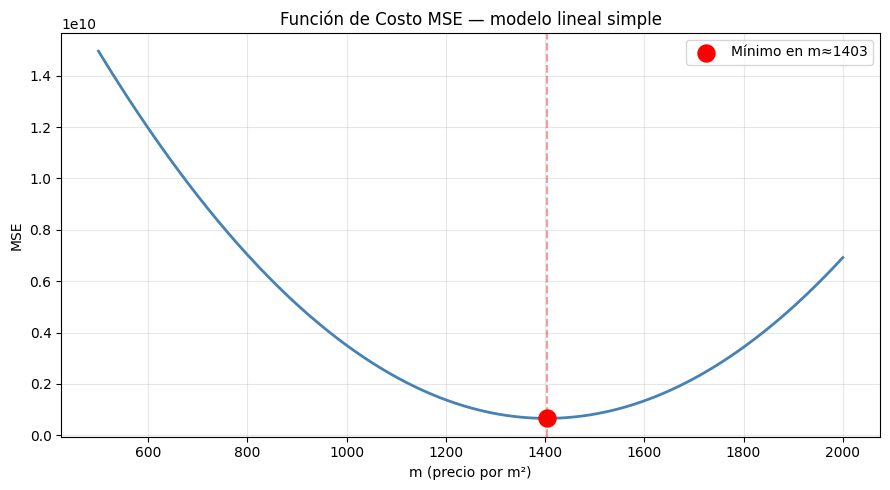


Valor óptimo de m: 1403.0 (precio por m²)
MSE mínimo: 660,076,020


In [12]:
# Graficar MSE en función de m
m_values = np.linspace(500, 2000, 300)
mse_values = [mse(m, x_data, y_data) for m in m_values]

m_optimo = m_values[np.argmin(mse_values)]
mse_optimo = min(mse_values)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(m_values, mse_values, color='steelblue', linewidth=2)
ax.scatter([m_optimo], [mse_optimo], color='red', s=150, zorder=5, label=f'Mínimo en m≈{m_optimo:.0f}')
ax.axvline(m_optimo, color='red', linestyle='--', alpha=0.4)
ax.set_xlabel('m (precio por m²)')
ax.set_ylabel('MSE')
ax.set_title('Función de Costo MSE — modelo lineal simple')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nValor óptimo de m: {m_optimo:.1f} (precio por m²)")
print(f"MSE mínimo: {mse_optimo:,.0f}")

## 2. Superficie de Costo 3D (dos parámetros)

El modelo completo `ŷ = m*x + b` tiene dos parámetros. El costo es una superficie en 3D.

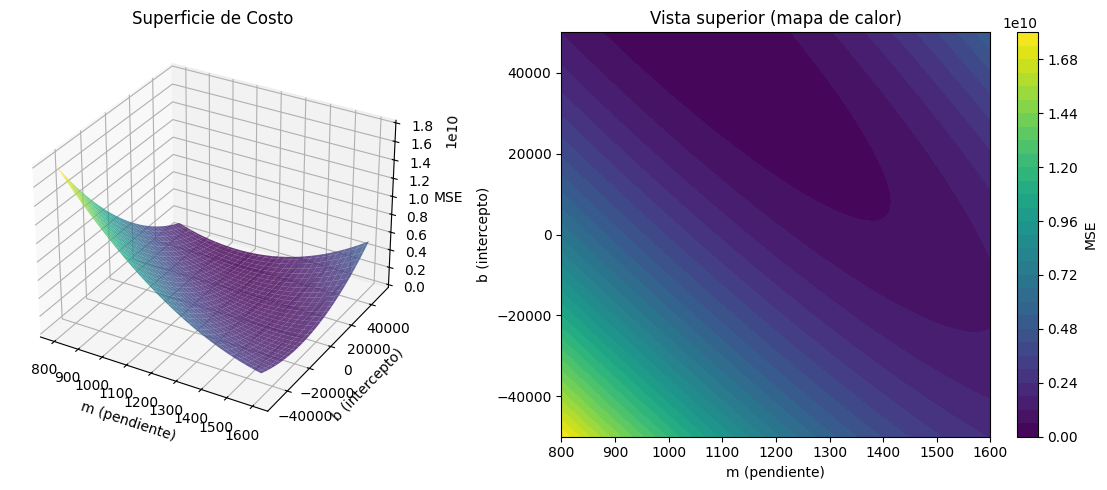

El punto más oscuro (menor MSE) es la solución óptima.


In [13]:
def mse_2d(m, b, x, y):
    return np.mean((m * x + b - y) ** 2)

# Crear grilla de valores (m, b)
m_range = np.linspace(800, 1600, 60)
b_range = np.linspace(-50000, 50000, 60)
M, B = np.meshgrid(m_range, b_range)

# Calcular MSE para cada combinación de m y b
MSE_grid = np.array([[mse_2d(m, b, x_data, y_data) for m in m_range] for b in b_range])

fig = plt.figure(figsize=(12, 5))

# Superficie 3D
ax1 = fig.add_subplot(121, projection='3d')
surf = ax1.plot_surface(M, B, MSE_grid, cmap='viridis', alpha=0.8)
ax1.set_xlabel('m (pendiente)')
ax1.set_ylabel('b (intercepto)')
ax1.set_zlabel('MSE')
ax1.set_title('Superficie de Costo')

# Mapa de calor (contour plot)
ax2 = fig.add_subplot(122)
cp = ax2.contourf(M, B, MSE_grid, levels=30, cmap='viridis')
plt.colorbar(cp, ax=ax2, label='MSE')
ax2.set_xlabel('m (pendiente)')
ax2.set_ylabel('b (intercepto)')
ax2.set_title('Vista superior (mapa de calor)')

plt.tight_layout()
plt.show()
print("El punto más oscuro (menor MSE) es la solución óptima.")

## 3. Límites: la idea de acercarse

La derivada se define como un límite. Exploramos numéricamente cómo `(f(x+h) - f(x))/h` converge cuando `h → 0`.

In [16]:
# Función simple: f(m) = m²
np.set_printoptions(suppress=True, precision=2)
f = lambda m: m**2

# La derivada de m² es 2m → en m=3, la derivada exacta es 6
m0 = 3.0
derivada_exacta = 2 * m0

print(f"Derivada exacta de f(m)=m² en m={m0}: {derivada_exacta}")
print("\nAproximación numérica con distintos h:")
print(f"{'h':>12} | {'aprox':>12} | {'error':>12}")
print("-" * 40)
for h in [1.0, 0.1, 0.01, 0.001, 0.0001, 1e-7]:
    aprox = (f(m0 + h) - f(m0)) / h
    error = abs(aprox - derivada_exacta)
    print(f"{h:>12.2e} | {aprox:>12.8f} | {error:>12.2e}")

Derivada exacta de f(m)=m² en m=3.0: 6.0

Aproximación numérica con distintos h:
           h |        aprox |        error
----------------------------------------
    1.00e+00 |   7.00000000 |     1.00e+00
    1.00e-01 |   6.10000000 |     1.00e-01
    1.00e-02 |   6.01000000 |     1.00e-02
    1.00e-03 |   6.00100000 |     1.00e-03
    1.00e-04 |   6.00010000 |     1.00e-04
    1.00e-07 |   6.00000009 |     8.79e-08


## 4. La Derivada como Pendiente de la Recta Tangente

La derivada en un punto es la pendiente de la recta tangente a la curva en ese punto.

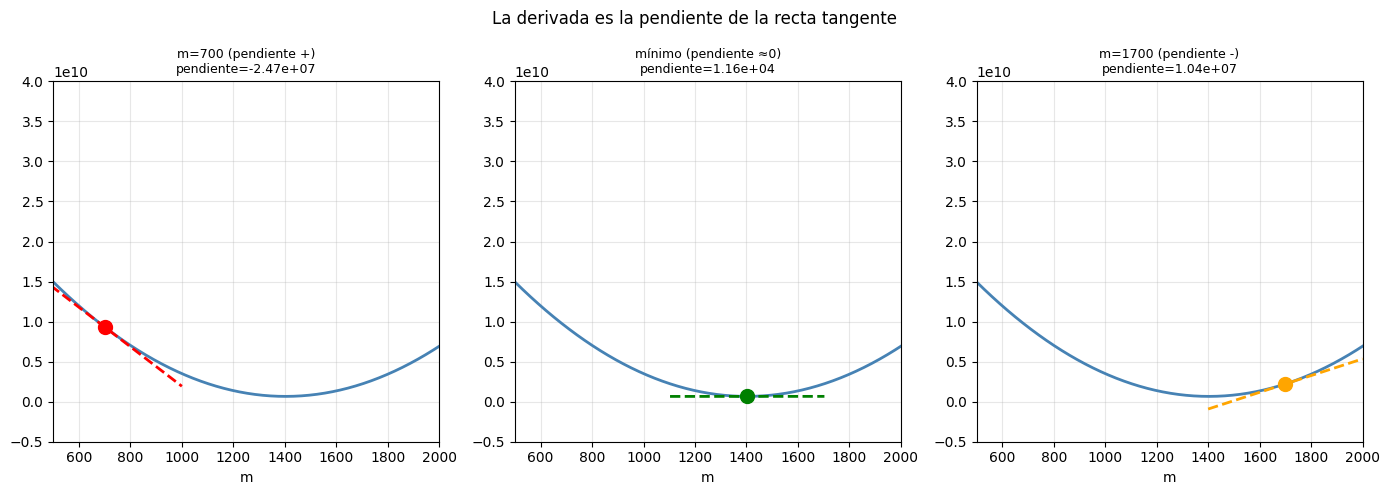

In [6]:
def derivada_numerica(f, x, h=1e-5):
    return (f(x + h) - f(x - h)) / (2 * h)  # diferencia central: más precisa

# Derivada del MSE (como función de m) en distintos puntos
f_mse = lambda m: mse(m, x_data, y_data)

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
m_plot = np.linspace(500, 2000, 200)
y_plot = [f_mse(m) for m in m_plot]

puntos_tangente = [700, m_optimo, 1700]
colores = ['red', 'green', 'orange']
etiquetas = ['m=700 (pendiente +)', 'mínimo (pendiente ≈0)', 'm=1700 (pendiente -)']

for ax, m_punto, color, etiqueta in zip(axes, puntos_tangente, colores, etiquetas):
    pendiente = derivada_numerica(f_mse, m_punto)
    y_punto = f_mse(m_punto)
    
    ax.plot(m_plot, y_plot, color='steelblue', linewidth=2)
    ax.scatter([m_punto], [y_punto], color=color, s=100, zorder=5)
    
    # Recta tangente: y = y0 + pendiente*(x - x0)
    x_tang = np.linspace(m_punto - 300, m_punto + 300, 50)
    y_tang = y_punto + pendiente * (x_tang - m_punto)
    ax.plot(x_tang, y_tang, color=color, linestyle='--', linewidth=2)
    
    ax.set_xlim(500, 2000)
    ax.set_ylim(-0.5e10, 4e10)
    ax.set_title(f'{etiqueta}\npendiente={pendiente:.2e}', fontsize=9)
    ax.set_xlabel('m')
    ax.grid(True, alpha=0.3)

plt.suptitle('La derivada es la pendiente de la recta tangente', fontsize=12)
plt.tight_layout()
plt.show()

## 5. Derivada Simbólica con SymPy

SymPy calcula derivadas exactas (simbólicas), no aproximaciones numéricas.

In [7]:
m, b, x_sym, y_sym, n = sp.symbols('m b x y n', real=True)

# Error cuadrático para una muestra
error_cuadrado = (m * x_sym + b - y_sym)**2
print("Error cuadrático:", error_cuadrado)

# Derivada respecto a m
d_dm = sp.diff(error_cuadrado, m)
print("\n∂/∂m:", d_dm)
print("Simplificado:", sp.simplify(d_dm))

# Derivada respecto a b
d_db = sp.diff(error_cuadrado, b)
print("\n∂/∂b:", d_db)
print("Simplificado:", sp.simplify(d_db))

Error cuadrático: (b + m*x - y)**2

∂/∂m: 2*x*(b + m*x - y)
Simplificado: 2*x*(b + m*x - y)

∂/∂b: 2*b + 2*m*x - 2*y
Simplificado: 2*b + 2*m*x - 2*y


In [8]:
# El MSE completo como función de m (sin b, para un modelo simple)
# MSE(m) = (1/n) * sum((m*xi - yi)^2)
# En forma simbólica, usamos la versión continua para ver la forma

mse_sym = (m * x_sym - y_sym)**2
grad_m = sp.diff(mse_sym, m)
print("Gradiente de MSE respecto a m:")
sp.pprint(grad_m)
print("\nEsto nos dice: para actualizar m, calculamos el promedio de 2*xi*(m*xi - yi)")
print("Que es exactamente lo que implementaremos en la Unidad 4.")

Gradiente de MSE respecto a m:
2⋅x⋅(m⋅x - y)

Esto nos dice: para actualizar m, calculamos el promedio de 2*xi*(m*xi - yi)
Que es exactamente lo que implementaremos en la Unidad 4.


In [9]:
# Verificar: la derivada numérica vs la simbólica evaluada
m_test = 1200.0

# Numérica
grad_numerico = derivada_numerica(f_mse, m_test)

# Simbólica evaluada numéricamente: (2/n) * sum(xi * (m*xi - yi))
grad_simbolico = (2 / len(x_data)) * np.sum(x_data * (m_test * x_data - y_data))

print(f"Gradiente numérico en m={m_test}:  {grad_numerico:.2f}")
print(f"Gradiente simbólico en m={m_test}: {grad_simbolico:.2f}")
print(f"Diferencia: {abs(grad_numerico - grad_simbolico):.4f}")

Gradiente numérico en m=1200.0:  -7111999.98
Gradiente simbólico en m=1200.0: -7112000.00
Diferencia: 0.0234


## Ejercicios

**Ejercicio 1:** Graficá la función `f(x) = x³ - 3x + 1` en el rango [-2, 2]. Calculá su derivada con SymPy y graficala en el mismo rango. ¿Dónde es cero la derivada?

**Ejercicio 2:** Calculá la derivada numérica de MSE en los puntos `m = 900, 1100, 1300, 1500`. ¿En cuál es más cercana a cero?

**Ejercicio 3:** Modificá el modelo para incluir el bias: `ŷ = m*x + b`. Graficá el MSE en función de `b` manteniendo `m = 1200` fijo. ¿Cuál es el `b` óptimo?

In [ ]:
# Ejercicio 1


In [ ]:
# Ejercicio 2


In [ ]:
# Ejercicio 3
